Chapter 3: Group Comparisons

Context:
A computer company has two email lists, desktop subscribers and laptop subscribers, and is about to email both about a new product. The chapter first builds the statistics using heights of 1,034 MLB players, then applies them to the email lists.

Problem:
Decide whether two groups really differ or are just random samples from the same population. For the business: should the marketing team send one email to everyone, or a different email to each list?

Solution:
Compare random samples, simulate 1,000 differences between sample means to estimate a p-value, then use hypothesis testing (t-test, Mann-Whitney U test) at a 5% significance level.

Tools:
pandas, NumPy, Matplotlib, seaborn, SciPy (scipy.stats)

Implementation:

In [1]:
!wget -q https://bradfordtuckfield.com/mlb.csv
!wget -q https://bradfordtuckfield.com/desktop.csv
!wget -q https://bradfordtuckfield.com/laptop.csv

In [2]:
import pandas as pd
mlb=pd.read_csv('mlb.csv')
print(mlb.head())
print(mlb.shape)
print(mlb.describe())

              name team       position  height  weight    age
0    Adam_Donachie  BAL        Catcher      74   180.0  22.99
1        Paul_Bako  BAL        Catcher      74   215.0  34.69
2  Ramon_Hernandez  BAL        Catcher      72   210.0  30.78
3     Kevin_Millar  BAL  First_Baseman      72   210.0  35.43
4      Chris_Gomez  BAL  First_Baseman      73   188.0  35.71
(1034, 6)
            height       weight          age
count  1034.000000  1033.000000  1034.000000
mean     73.697292   201.689255    28.736712
std       2.305818    20.991491     4.320310
min      67.000000   150.000000    20.900000
25%      72.000000   187.000000    25.440000
50%      74.000000   200.000000    27.925000
75%      75.000000   215.000000    31.232500
max      83.000000   290.000000    48.520000


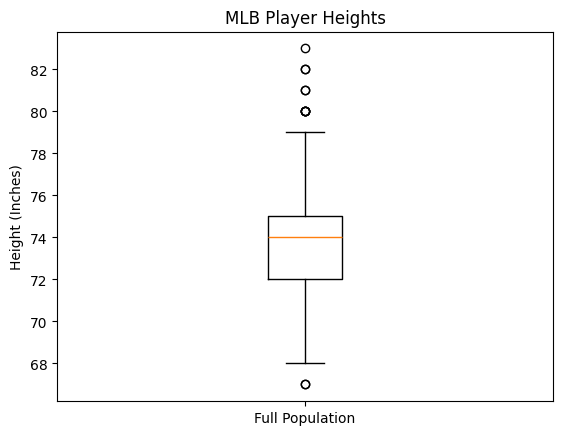

In [3]:
import matplotlib.pyplot as plt
fig1, ax1 = plt.subplots()
ax1.boxplot([mlb['height']])
ax1.set_ylabel('Height (Inches)')
plt.title('MLB Player Heights')
plt.xticks([1], ['Full Population'])
plt.show()

Take two random samples of 30 players, plus a mystery sample3. Is sample3 from the same population?

In [4]:
sample1=mlb.sample(n=30,random_state=8675309)
sample2=mlb.sample(n=30,random_state=1729)
sample3=[71, 72, 73, 74, 74, 76, 75, 75, 75, 76, 75, 77, 76, 75, 77, 76, 75,\
76, 76, 75, 75, 81,77, 75, 77, 75, 77, 77, 75, 75]

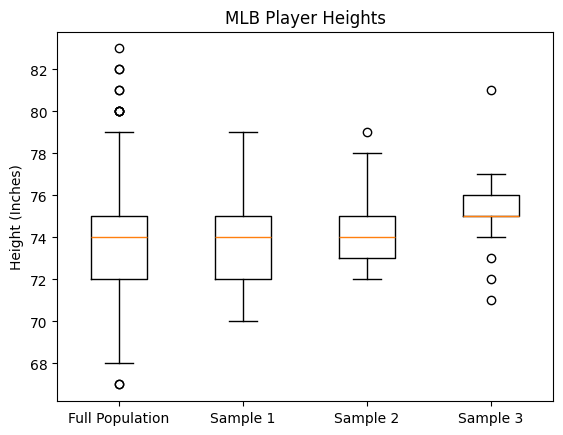

In [5]:
import numpy as np
fig1, ax1 = plt.subplots()
ax1.boxplot([mlb['height'],sample1['height'],sample2['height'],np.array(sample3)])
ax1.set_ylabel('Height (Inches)')
plt.title('MLB Player Heights')
plt.xticks([1,2,3,4], ['Full Population','Sample 1','Sample 2','Sample 3'])
plt.show()

In [6]:
print(np.mean(sample1['height']))
print(np.mean(sample2['height']))
print(np.mean(sample3))

73.8
74.36666666666666
75.43333333333334


How big a difference between sample means is normal? Simulate 1,000 pairs of random samples.

In [7]:
alldifferences=[]
for i in range(1000):
    newsample1=mlb.sample(n=30,random_state=i*2)
    newsample2=mlb.sample(n=30,random_state=i*2+1)
    alldifferences.append(newsample1['height'].mean()-newsample2['height'].mean())

print(alldifferences[0:10])

[np.float64(0.8333333333333286), np.float64(-0.30000000000001137), np.float64(-0.10000000000000853), np.float64(-0.1666666666666572), np.float64(0.06666666666667709), np.float64(-0.9666666666666686), np.float64(0.7999999999999972), np.float64(0.9333333333333371), np.float64(-0.5333333333333314), np.float64(-0.20000000000000284)]


/tmp/ipykernel_25242/2366243221.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax=sns.distplot(alldifferences).set_title("Differences Between Sample Means")


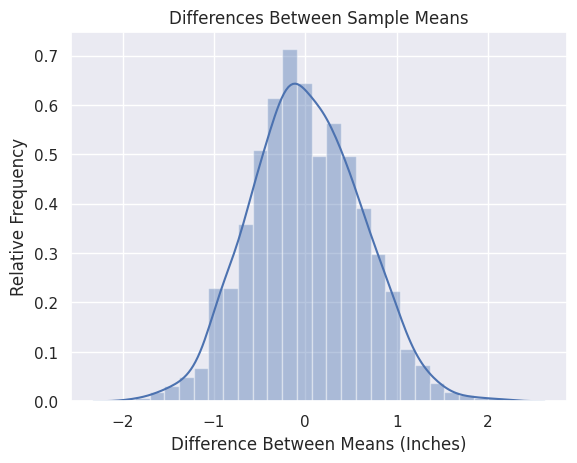

In [8]:
import seaborn as sns
sns.set()
ax=sns.distplot(alldifferences).set_title("Differences Between Sample Means")
plt.xlabel('Difference Between Means (Inches)')
plt.ylabel('Relative Frequency')
plt.show()

In [9]:
largedifferences=[diff for diff in alldifferences if abs(diff)>=1.6]
print(len(largedifferences))

smalldifferences=[diff for diff in alldifferences if abs(diff)>=0.6]
print(len(smalldifferences))

8
314


A 1.6-inch difference happens only about 0.8% of the time, so sample3 is probably not from the MLB population. A 0.6-inch difference happens about 31% of the time, so sample1 and sample2 plausibly are.

Hypothesis 0: the two samples come from the same population.
Hypothesis 1: they do not. Reject H0 if p < 0.05.

In [10]:
import scipy.stats
print(scipy.stats.ttest_ind(sample1['height'],sample2['height']))
print(scipy.stats.ttest_ind(sample1['height'],sample3))
print(scipy.stats.mannwhitneyu(sample1['height'],sample2['height']))

TtestResult(statistic=np.float64(-1.0839563860213952), pvalue=np.float64(0.2828695892305152), df=np.float64(58.0))
TtestResult(statistic=np.float64(-3.108694797644094), pvalue=np.float64(0.002910554741439718), df=np.float64(58.0))
MannwhitneyuResult(statistic=np.float64(392.0), pvalue=np.float64(0.38913738408151577))


Practical example: do desktop and laptop email subscribers differ?

In [11]:
desktop=pd.read_csv('desktop.csv')
laptop=pd.read_csv('laptop.csv')
print(desktop.head())
print(laptop.head())

   userid  spending  age  visits
0       1      1250   31     126
1       2       900   27       5
2       3         0   30     459
3       4      2890   22      18
4       5      1460   38      20
   userid  spending  age  visits
0      31      1499   32      12
1      32       799   23      40
2      33      1200   45      22
3      34         0   59     126
4      35      1350   17      85


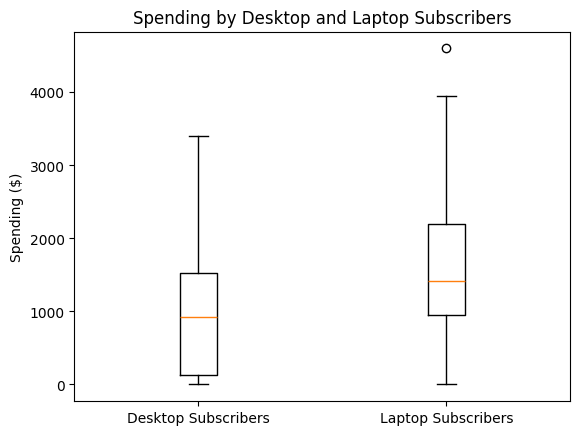

In [12]:
import matplotlib.pyplot as plt
sns.reset_orig()
fig1, ax1 = plt.subplots()
ax1.set_title('Spending by Desktop and Laptop Subscribers')
ax1.boxplot([desktop['spending'].values,laptop['spending'].values])
ax1.set_ylabel('Spending ($)')
plt.xticks([1,2], ['Desktop Subscribers','Laptop Subscribers'])
plt.show()

In [13]:
print(np.mean(desktop['age']))
print(np.mean(laptop['age']))
print(np.median(desktop['age']))
print(np.median(laptop['age']))
print(np.quantile(laptop['spending'],.25))
print(np.quantile(desktop['spending'],.75))
print(np.std(desktop['age']))

35.766666666666666
38.733333333333334
32.0
33.0
957.5
1528.25
14.943634839697543


In [14]:
print(scipy.stats.ttest_ind(desktop['spending'],laptop['spending']))

TtestResult(statistic=np.float64(-2.109853741030508), pvalue=np.float64(0.03919630411621095), df=np.float64(58.0))


Conclusion:
Random samples from one population look similar, and simulating 1,000 sample pairs showed how large a difference is normal. sample1 and sample2 are plausibly from the same population (p ≈ 0.28), while sample3 is not (p < 0.05). For the business, the t-test on spending gave p ≈ 0.04 < 0.05, so desktop and laptop subscribers differ, and the marketing team should send them different emails. Remember: a p-value isn't the probability a hypothesis is true, and statistical significance doesn't always mean practical significance.